# Fase 3b: efeito da Lei 14.300 com degraus na taxa

Variante do [notebook 03](03_intervencao.ipynb). Aqui cada regime é um degrau na taxa de crescimento (mar/2020, corrida,
pós-corrida), sem queda de nível, e o efeito é medido em GW por contrafactuais. É a especificação do modelo de intervenção
que entra na comparação da fase 4 ([`src/modelos.py`](../src/modelos.py)).

Mede quanto da corrida de 2022–2023 e da parada depois dela se deve à Lei 14.300, separando isso da
desaceleração que a série já mostrava desde 2020.

Entrada: `data/processed/aneel_serie_mensal_uf.parquet`. Modelos em [`src/modelos.py`](../src/modelos.py).
Referência: FPP3 cap. 10 (regressão com erros ARIMA), §7.4 (variáveis de intervenção), §5.4 (diagnóstico de resíduos);
Box & Tiao (1975). Os comentários foram escritos com o retrato da ANEEL de out/2026 (série até jun/2026).

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import acf

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import estilo
import modelos as M
from estilo import CORES_UF, UFS

%matplotlib inline
estilo.aplicar()
warnings.simplefilter("ignore")
pd.set_option("display.precision", 3)

RES = ROOT / "resultados"
TODAS = UFS + ["SE"]
serie, y = M.carregar(ROOT / "data" / "processed" / "aneel_serie_mensal_uf.parquet")
print(f"{y['SE'].index[0]:%Y-%m} a {y['SE'].index[-1]:%Y-%m}, {len(y['SE'])} meses por UF")

2016-01 a 2026-06, 126 meses por UF


## 1. Especificação

A fase 2 fixou o log, uma diferença ($d = 1$) e nenhuma diferença sazonal. Na série diferenciada, $\Delta \log y_t$ é a
taxa de crescimento mensal da potência adicionada. O modelo põe um degrau nessa taxa para cada regime:

$$\Delta \log y_t = \mu + \delta_1\, D^{2020}_t + \delta_2\, D^{\text{corrida}}_t + \delta_3\, D^{\text{pós}}_t + \eta_t,
\qquad \eta_t \sim \text{ARMA}(p, q)$$

| variável | vale 1 em | o que mede |
|---|---|---|
| $D^{2020}$ | mar/2020 em diante | a desaceleração anterior à lei (quebra do Zivot-Andrews em MG e no Sudeste) |
| $D^{\text{corrida}}$ | jan/2022 a jun/2023 | quanto a corrida para garantir a regra antiga mudou o crescimento, frente a 2020–21 |
| $D^{\text{pós}}$ | jul/2023 em diante | quanto o crescimento mudou depois da corrida, frente a 2020–21 |

A taxa de crescimento de cada regime é $\mu$ (2016 a fev/2020), $\mu + \delta_1$ (mar/2020 a dez/2021),
$\mu + \delta_1 + \delta_2$ (corrida) e $\mu + \delta_1 + \delta_3$ (depois). Em nível, cada degrau vira uma rampa, e é assim que
as variáveis entram no SARIMAX com $d = 1$ (regressão com erros ARIMA, cap. 10). As ordens $(p, q) \le 2$ saem por AICc (§9.6).

A corrida vai até jun/2023, e não até jan/2023 (o fim do prazo de protocolo), porque a conexão vem meses depois do pedido.

In [2]:
ajustes = {uf: M.ARIMA(nome=uf, exog="interv").fit(y[uf]) for uf in TODAS}

def tabela_coef(m):
    r = m.res
    ci = r.conf_int()
    nomes = ["t", *M.NOMES_INTERV]
    t = pd.DataFrame({"coef": r.params[nomes], "ic95_inf": ci.loc[nomes, 0], "ic95_sup": ci.loc[nomes, 1],
                      "p": r.pvalues[nomes]})
    return t.rename(index={"t": "μ (drift)", "desac_2020": "δ1 2020", "corrida": "δ2 corrida", "pos": "δ3 pós"})

coef = pd.concat({uf: tabela_coef(m) for uf, m in ajustes.items()})
ordens = pd.DataFrame({uf: {"ARIMA": f"({m.order[0]},1,{m.order[1]})", "AICc": M.aicc(m.res),
                            "σ (log)": np.sqrt(m.res.params['sigma2'])} for uf, m in ajustes.items()}).T
ordens

,ARIMA,AICc,σ (log)
SP,"(1,1,0)",-34.628,0.2
MG,"(0,1,1)",27.641,0.252
RJ,"(0,1,1)",41.31,0.271
ES,"(0,1,2)",91.362,0.327
SE,"(0,1,1)",-57.906,0.182


In [3]:
coef

coef  ic95_inf  ic95_sup          p
SP μ (drift)   1.021e-01     0.065     0.139  8.518e-08
   δ1 2020    -7.516e-02    -0.141    -0.009  2.522e-02
   δ2 corrida -1.624e-02    -0.098     0.066  6.970e-01
   δ3 pós     -1.847e-02    -0.103     0.067  6.702e-01
MG μ (drift)   9.289e-02     0.088     0.097  0.000e+00
   δ1 2020    -7.387e-02    -0.089    -0.059  1.769e-21
   δ2 corrida  2.288e-04    -0.026     0.027  9.866e-01
   δ3 pós     -3.032e-02    -0.043    -0.018  1.846e-06
RJ μ (drift)   7.306e-02     0.046     0.100  1.006e-07
   δ1 2020    -2.670e-02    -0.084     0.031  3.612e-01
   δ2 corrida -4.066e-02    -0.121     0.039  3.185e-01
   δ3 pós     -3.979e-02    -0.112     0.032  2.783e-01
ES μ (drift)   9.012e-02     0.054     0.126  1.155e-06
   δ1 2020    -3.973e-02    -0.146     0.067  4.643e-01
   δ2 corrida -4.688e-02    -0.172     0.079  4.638e-01
   δ3 pós     -3.240e-02    -0.152     0.087  5.963e-01
SE μ (drift)   9.333e-02     0.072     0.114  3.487e-18
   δ1 2020    -6.662e-02    -0.107    -0.026  1.264e-03
   δ2 corrida -1.233e-02    -0.062     0.037  6.249e-01
   δ3 pós     -2.591e-02    -0.081     0.029  3.540e-01

Os coeficientes estão em log por mês. Em taxa anual, um coeficiente $c$ equivale a $e^{12c} - 1$. A tabela abaixo mostra o
crescimento anual da potência adicionada por mês em cada regime, com intervalo de 95% calculado pela covariância dos
coeficientes:

In [4]:
REGIMES = {"2016 – fev/2020": ["t"], "mar/2020 – 2021": ["t", "desac_2020"],
           "corrida (jan/22 – jun/23)": ["t", "desac_2020", "corrida"], "depois (jul/23 – jun/26)": ["t", "desac_2020", "pos"]}

def anual(c):
    return 100 * (np.exp(12 * c) - 1)

linhas = []
for uf, m in ajustes.items():
    b, V = m.res.params, m.res.cov_params()
    for reg, cols in REGIMES.items():
        g, se = b[cols].sum(), np.sqrt(V.loc[cols, cols].to_numpy().sum())
        linhas.append({"UF": uf, "regime": reg, "cresc. anual": anual(g),
                       "IC95": f"[{anual(g - 1.96 * se):.0f}%, {anual(g + 1.96 * se):.0f}%]"})
tab_reg = pd.DataFrame(linhas).pivot(index="UF", columns="regime")
cresc = tab_reg["cresc. anual"][list(REGIMES)].loc[TODAS]
ic = tab_reg["IC95"][list(REGIMES)].loc[TODAS]
(cresc.round(0).astype(int).astype(str) + "% " + ic)

regime,2016 – fev/2020,mar/2020 – 2021,corrida (jan/22 – jun/23),depois (jul/23 – jun/26)
UF,,,,
SP,"240% [117%, 433%]","38% [-28%, 164%]","14% [-45%, 137%]","11% [-50%, 142%]"
MG,"205% [189%, 222%]","26% [9%, 45%]","26% [4%, 53%]","-13% [-21%, -3%]"
RJ,"140% [74%, 232%]","74% [-6%, 224%]","7% [-46%, 114%]","8% [-41%, 97%]"
ES,"195% [91%, 356%]","83% [-43%, 492%]","4% [-62%, 186%]","24% [-47%, 190%]"
SE,"206% [138%, 295%]","38% [-8%, 106%]","19% [-22%, 82%]","1% [-40%, 70%]"


## 2. Diagnóstico dos resíduos

Os resíduos devem ser ruído branco (§5.4): sem autocorrelação (Ljung-Box com 12 e 24 defasagens, descontando os
graus de liberdade do ARMA) e, de preferência, perto da normal, porque os intervalos de previsão supõem isso.

In [5]:
diag = []
for uf, m in ajustes.items():
    e = m.resid
    lb = acorr_ljungbox(e, lags=[12, 24], model_df=sum(m.order))["lb_pvalue"]
    jb = stats.jarque_bera(e)
    diag.append({"UF": uf, "Ljung-Box 12 p": lb.iloc[0], "Ljung-Box 24 p": lb.iloc[1],
                 "Jarque-Bera p": jb.pvalue, "assimetria": stats.skew(e), "curtose exc.": stats.kurtosis(e)})
tab_diag = pd.DataFrame(diag).set_index("UF")
tab_diag

,Ljung-Box 12 p,Ljung-Box 24 p,Jarque-Bera p,assimetria,curtose exc.
UF,,,,,
SP,0.290,1.874e-01,0.890,-0.044,-0.193
MG,0.003,4.490e-04,0.471,0.269,0.005
RJ,0.230,4.205e-01,0.009,0.584,0.679
ES,0.002,3.644e-04,0.020,-0.089,1.211
SE,0.109,3.337e-01,0.324,-0.156,0.580


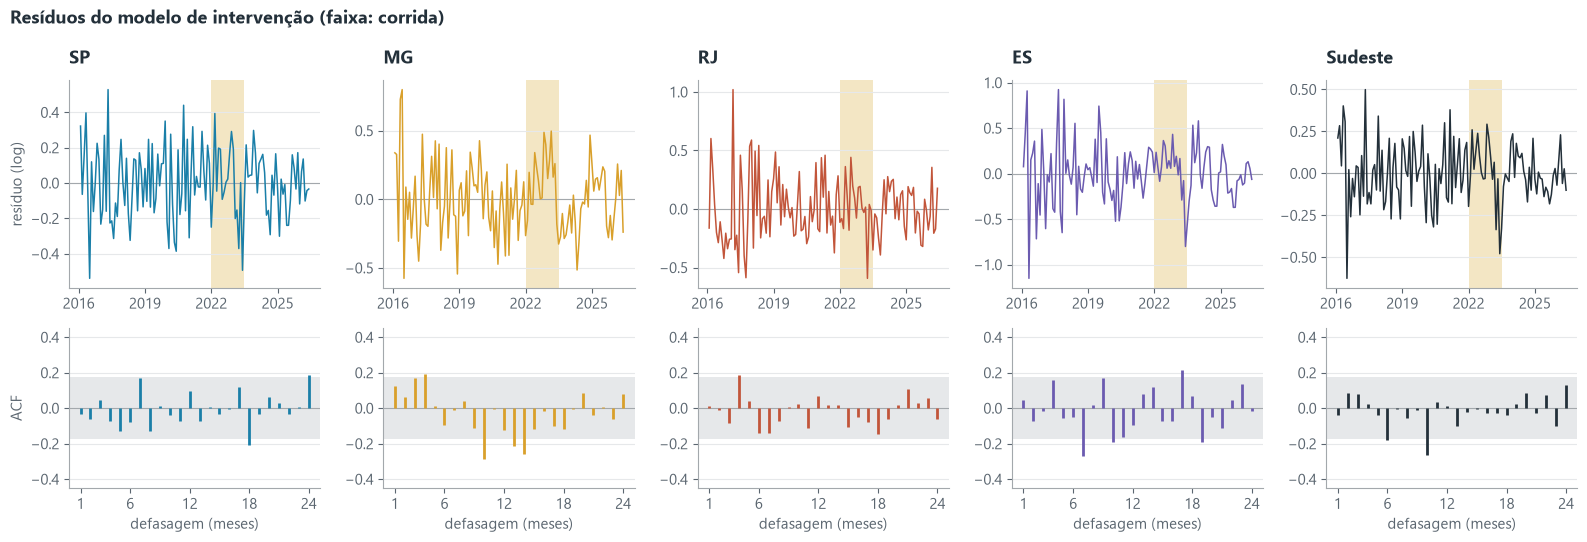

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(16, 5.5), gridspec_kw={"height_ratios": [1.3, 1]})
for j, uf in enumerate(TODAS):
    e = ajustes[uf].resid
    cor = CORES_UF.get(uf, estilo.TINTA)
    ax = axes[0, j]
    ax.axhline(0, color=estilo.NEUTRO, lw=0.8)
    ax.plot(e.index, e, color=cor, lw=1.1)
    ax.axvspan(*M.CORRIDA, color=estilo.DESTAQUE, lw=0, zorder=0)
    ax.set_title(uf if uf != "SE" else "Sudeste")
    ax.xaxis.set_major_locator(mdates.YearLocator(3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax = axes[1, j]
    banda = 1.96 / np.sqrt(len(e))
    ax.axhspan(-banda, banda, color=estilo.GRADE, lw=0)
    ax.axhline(0, color=estilo.NEUTRO, lw=0.8)
    ax.vlines(range(1, 25), 0, acf(e, nlags=24)[1:], color=cor, lw=2)
    ax.set_xticks([1, 6, 12, 18, 24])
    ax.set_ylim(-0.45, 0.45)
    ax.set_xlabel("defasagem (meses)")
axes[0, 0].set_ylabel("resíduo (log)")
axes[1, 0].set_ylabel("ACF")
fig.suptitle("Resíduos do modelo de intervenção (faixa: corrida)", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(RES / "interv_residuos.png")

**Leitura.**
- Em SP, RJ e no Sudeste os resíduos passam no Ljung-Box (p > 0,1). A distribuição é próxima da normal, com caudas um pouco pesadas em RJ e ES.
- Em **MG e ES sobra autocorrelação** (p < 0,01). Ela está em defasagens isoladas, sobretudo a 10 (−0,2 a −0,3), e não no lag 1 nem no 12. É o mesmo calendário de conexões que aparece no perfil sazonal da fase 2 (picos em maio e dezembro).
- Testamos dummies de mês no nível do log. Pelo AICc elas só ajudam SP e pioram MG e ES; também não limpam o Ljung-Box do Sudeste. Mudam pouco as estimativas: $\hat\delta_3$ no Sudeste vai de −0,026 para −0,028. Ficaram de fora. A consequência é que os intervalos de MG e ES devem estar um pouco estreitos.
- Em MG o MA(1) fica em −1, na fronteira da invertibilidade. A seção 3 trata disso.

### Ordens maiores resolvem?

A busca por AICc vai até $(p, q) \le 2$. Para ver se a autocorrelação de MG e ES é falta de ordem, o modelo é reajustado
com todas as ordens até $(3, 3)$, nas duas versões ($d = 1$ e a de tendência quebrada, $d = 0$, da seção 3), e com um MA
esparso nas defasagens 1 e 10, onde está a autocorrelação. A tabela mostra a melhor ordem por AICc, a ordem com maior
p-valor no Ljung-Box de 24 defasagens e o MA esparso, com o $\hat\delta_3$ (pós-corrida) de cada um.

In [7]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

def ajuste_ordem(uf, exog, p, q):
    # p, q: inteiro (ordem) ou lista de defasagens (termos esparsos)
    d = 0 if exog == "quebrada" else 1
    X = M.rampas(y[uf].index, y[uf].index[0])[["t", *M.NOMES_INTERV]]
    if exog == "quebrada":
        X.insert(0, "const", 1.0)
    r = M._fit(SARIMAX(y[uf], exog=X, order=(p, d, q), trend="n"))
    gl = sum(len(o) if isinstance(o, list) else o for o in (p, q))
    lb = acorr_ljungbox(r.resid.iloc[d:], lags=[12, 24], model_df=gl)["lb_pvalue"]
    return {"AICc": M.aicc(r), "LB 12 p": lb.iloc[0], "LB 24 p": lb.iloc[1],
            "δ3 pós": r.params["pos"], "p δ3": r.pvalues["pos"]}

linhas = []
for uf in ["MG", "ES"]:
    for exog, versao in [("interv", "d=1"), ("quebrada", "d=0")]:
        g = pd.DataFrame([{"ARMA": f"({p},{q})", **ajuste_ordem(uf, exog, p, q)}
                          for p in range(4) for q in range(4)])
        esparso = pd.Series({"ARMA": "MA(1,10)", **ajuste_ordem(uf, exog, 0, [1, 10])})
        for criterio, linha in [("menor AICc", g.loc[g["AICc"].idxmin()]),
                                ("maior LB 24 p", g.loc[g["LB 24 p"].idxmax()]),
                                ("MA esparso", esparso)]:
            linhas.append({"UF": uf, "versão": versao, "critério": criterio, **linha.to_dict()})
ordens = pd.DataFrame(linhas).set_index(["UF", "versão", "critério"])
ordens

ARMA    AICc    LB 12 p    LB 24 p  δ3 pós  \
UF versão critério                                                        
MG d=1    menor AICc        (0,1)  27.641  3.369e-03  4.490e-04  -0.030   
          maior LB 24 p     (3,0)  36.604  3.576e-01  3.977e-01  -0.018   
          MA esparso     MA(1,10)  23.573  9.197e-02  1.951e-01  -0.028   
   d=0    menor AICc        (0,0)  21.875  2.366e-02  3.805e-03  -0.030   
          maior LB 24 p     (3,3)  26.195  2.736e-01  3.674e-01  -0.027   
          MA esparso     MA(1,10)  14.511  8.238e-01  3.443e-01  -0.030   
ES d=1    menor AICc        (3,3)  85.169  9.354e-04  6.760e-03  -0.037   
          maior LB 24 p     (3,3)  85.169  9.354e-04  6.760e-03  -0.037   
          MA esparso     MA(1,10)  86.276  1.550e-03  4.085e-04  -0.053   
   d=0    menor AICc        (1,3)  82.485  8.359e-04  3.285e-04  -0.052   
          maior LB 24 p     (1,3)  82.485  8.359e-04  3.285e-04  -0.052   
          MA esparso     MA(1,10)  93.542  3.469e-08  2.025e-12  -0.049   

                              p δ3  
UF versão critério                  
MG d=1    menor AICc     1.846e-06  
          maior LB 24 p  5.845e-01  
          MA esparso     2.029e-02  
   d=0    menor AICc     9.225e-07  
          maior LB 24 p  7.587e-03  
          MA esparso     3.800e-08  
ES d=1    menor AICc     4.507e-01  
          maior LB 24 p  4.507e-01  
          MA esparso     1.642e-01  
   d=0    menor AICc     3.381e-02  
          maior LB 24 p  3.381e-02  
          MA esparso     9.681e-13

**Leitura.**
- **Em ES nenhuma especificação passa no Ljung-Box** (p < 0,01 em todas, inclusive em $(3, 3)$ e no MA esparso). A autocorrelação
  está espalhada em defasagens isoladas e não tem estrutura ARMA de ordem baixa.
- **Em MG, ordens maiores passam, mas trocam o problema.** O AR(3) com $d = 1$ passa no teste, mas tem AICc 9 pontos pior e deixa
  $\hat\delta_3$ não significativo (p = 0,58), porque os três coeficientes AR absorvem parte da mudança de inclinação. O MA esparso
  (1, 10) passa e melhora o AICc, mas o termo na defasagem 10 não tem interpretação: nenhum calendário de conexões se repete
  a cada 10 meses. Seria ajustar o modelo para passar no teste.
- **$\hat\delta_3$ quase não muda.** Fica entre −0,027 e −0,030 em MG e entre −0,037 e −0,053 em ES em todas as alternativas, menos o
  AR(3) de MG. A conclusão sobre o regime pós-corrida não depende da ordem.
- Os modelos ficam como estão, com $(p, q) \le 2$ por AICc. Para as fases 4 e 5, o que importa é se a autocorrelação deixa os
  intervalos estreitos demais. A fase 4 verifica isso diretamente pela cobertura dos intervalos na validação cruzada.

## 3. Robustez: tendência determinística

Em MG o MA(1) estimado fica perto de −1. Isso é sinal de que, depois de modelar as quebras, a série em log não tem
raiz unitária: ela oscila em torno de uma tendência linear por partes (FPP3 §9.9; Perron, 1989). Para ver se a conclusão
depende disso, o mesmo modelo é reajustado sem diferença ($d = 0$): log y = tendência linear por partes, com as mesmas
datas de quebra, + ARMA(p, q).

In [8]:
quebrada = {uf: M.ARIMA(nome=uf, exog="quebrada").fit(y[uf]) for uf in TODAS}
comp = []
for uf in TODAS:
    for nome, m in [("d=1 (estocástica)", ajustes[uf]), ("d=0 (determinística)", quebrada[uf])]:
        b, se, p = m.res.params, m.res.bse, m.res.pvalues
        comp.append({"UF": uf, "modelo": nome, "ARMA": f"({m.order[0]},{m.order[1]})",
                     "δ2 corrida": b["corrida"], "p δ2": p["corrida"], "δ3 pós": b["pos"], "p δ3": p["pos"],
                     "cresc. depois %/ano": anual(b[["t", "desac_2020", "pos"]].sum())})
pd.DataFrame(comp).set_index(["UF", "modelo"])

ARMA  δ2 corrida   p δ2  δ3 pós       p δ3  \
UF modelo                                                              
SP d=1 (estocástica)     (1,0)  -1.624e-02  0.697  -0.018  6.702e-01   
   d=0 (determinística)  (1,2)  -1.180e-02  0.582  -0.054  8.369e-05   
MG d=1 (estocástica)     (0,1)   2.288e-04  0.987  -0.030  1.846e-06   
   d=0 (determinística)  (0,0)   2.064e-04  0.986  -0.030  9.225e-07   
RJ d=1 (estocástica)     (0,1)  -4.066e-02  0.319  -0.040  2.783e-01   
   d=0 (determinística)  (1,1)  -4.873e-02  0.075  -0.052  1.169e-03   
ES d=1 (estocástica)     (0,2)  -4.688e-02  0.464  -0.032  5.963e-01   
   d=0 (determinística)  (1,2)  -1.234e-02  0.779  -0.052  5.636e-02   
SE d=1 (estocástica)     (0,1)  -1.233e-02  0.625  -0.026  3.540e-01   
   d=0 (determinística)  (2,0)  -7.949e-03  0.599  -0.042  1.499e-05   

                         cresc. depois %/ano  
UF modelo                                     
SP d=1 (estocástica)                  10.657  
   d=0 (determinística)               -8.261  
MG d=1 (estocástica)                 -12.680  
   d=0 (determinística)              -12.697  
RJ d=1 (estocástica)                   8.198  
   d=0 (determinística)                5.641  
ES d=1 (estocástica)                  24.113  
   d=0 (determinística)                2.451  
SE d=1 (estocástica)                   0.971  
   d=0 (determinística)               -7.858

**Leitura.**
- **A corrida ($\delta_2$) não é significativa em nenhuma UF e em nenhuma das duas versões.** O crescimento durante a corrida não foi maior que o de 2020–21, e em SP, RJ e ES foi até menor. A corrida segurou o ritmo de 2020–21 por mais um ano e meio. No Sudeste, o crescimento passa de 38% ao ano em 2020–21 para 19% na corrida, uma diferença dentro do intervalo.
- **Depois da corrida ($\delta_3$), o crescimento cai.** A estimativa é de −0,026 a −0,054 log por mês, ou seja, de 27% a 48% a menos por ano que em 2020–21, em todas as UFs e nas duas versões. Com tendência determinística ($d = 0$) a queda é significativa em SP, MG, RJ e no Sudeste (p < 0,01) e quase em ES (p = 0,06). Com tendência estocástica ($d = 1$) ela só é significativa em MG.
- A diferença entre as versões é o tamanho do erro-padrão, não o sinal. Num passeio aleatório, uma mudança de inclinação é difícil de distinguir de um choque permanente. Numa tendência determinística, ela se destaca do ruído.
- Os dois modelos dizem a mesma coisa sobre o regime atual: no Sudeste a potência adicionada por mês está **estável** (entre −8% e +1% ao ano), contra 38% ao ano em 2020–21. MG é o único caso de queda clara (−13% ao ano nas duas versões).

## 4. Contrafactual: o que se esperava sem a lei

Os coeficientes dizem quanto a **taxa** mudou. Para traduzir isso em MW, cada modelo é ajustado só com dados até
dez/2021 (antes da lei) e projetado de jan/2022 a jun/2026, como se a lei não existisse. O efeito é a diferença entre
o observado e essa projeção, separada em corrida (jan/22 a jun/23) e depois (jul/23 a jun/26).

O resultado depende do que se supõe para o futuro sem lei, então há três contrafactuais:
- **regime 2020–21**: o modelo de intervenção só com $D^{2020}$, ou seja, o crescimento de 2020–21 continua;
- **tendência quebrada**: a versão $d = 0$ do mesmo modelo;
- **ETS amortecido**: o crescimento continua, mas perde força aos poucos (ETS(A,Ad,N) no log, cap. 8).

Os leques têm 4.000 caminhos simulados, com incerteza do ruído e dos coeficientes.

In [9]:
ANTES = "2021-12-01"
H = len(y["SE"][M.CORRIDA[0]:])
N_SIM = 4000
z = np.random.default_rng(0).standard_normal((H, N_SIM))
CONTRAF = {
    "regime 2020–21": lambda: M.ARIMA(exog="interv", interv=("desac_2020",)),
    "tendência quebrada": lambda: M.ARIMA(exog="quebrada", interv=("desac_2020",)),
    "ETS amortecido": lambda: M.ETS(),
}
idx_cf = y["SE"][M.CORRIDA[0]:].index
n_cor = int((idx_cf < M.CORRIDA[1]).sum())
sims, linhas = {}, []
for uf in TODAS:
    obs = np.exp(y[uf][M.CORRIDA[0]:])
    for nome, fab in CONTRAF.items():
        m = fab().fit(y[uf][:ANTES])
        s = np.exp(m.simulate(H, z, rng=np.random.default_rng(1)))
        sims[uf, nome] = s
        for periodo, sl in [("corrida", slice(0, n_cor)), ("depois", slice(n_cor, H)), ("total", slice(0, H))]:
            cf = s[sl].sum(axis=0) / 1e3
            o = obs.iloc[sl].sum() / 1e3
            linhas.append({"UF": uf, "contrafactual": nome, "período": periodo, "observado GW": o,
                           "contraf. P50": np.median(cf), "P10": np.quantile(cf, 0.1), "P90": np.quantile(cf, 0.9),
                           "efeito GW": o - np.median(cf), "efeito %": 100 * (o / np.median(cf) - 1),
                           "P(contraf. < obs)": (cf < o).mean()})
efeito = pd.DataFrame(linhas).set_index(["UF", "contrafactual", "período"])
efeito.loc["SE"]

observado GW  contraf. P50     P10     P90  \
contrafactual      período                                               
regime 2020–21     corrida         4.509         3.769   2.876   4.966   
                   depois          8.811        16.715   7.641  37.630   
                   total          13.320        20.433  10.666  42.416   
tendência quebrada corrida         4.509         3.469   2.865   4.165   
                   depois          8.811        15.048  10.418  21.853   
                   total          13.320        18.564  13.306  26.011   
ETS amortecido     corrida         4.509         4.027   2.918   5.594   
                   depois          8.811        13.928   7.358  26.560   
                   total          13.320        18.009  10.617  31.813   

                            efeito GW  efeito %  P(contraf. < obs)  
contrafactual      período                                          
regime 2020–21     corrida      0.741    19.654              0.797  
                   depois      -7.904   -47.287              0.150  
                   total       -7.112   -34.809              0.208  
tendência quebrada corrida      1.040    29.972              0.964  
                   depois      -6.237   -41.445              0.029  
                   total       -5.243   -28.245              0.101  
ETS amortecido     corrida      0.482    11.967              0.673  
                   depois      -5.117   -36.738              0.179  
                   total       -4.689   -26.036              0.235

In [10]:
# efeito por UF (P50 do contrafactual), em GW e em % do contrafactual
resumo_ef = efeito.reset_index().pivot_table(index=["UF", "contrafactual"], columns="período",
                                              values=["efeito GW", "efeito %"])
resumo_ef = resumo_ef.reindex(columns=["corrida", "depois", "total"], level=1)
resumo_ef.loc[TODAS].round(2)

efeito %               efeito GW             
período                corrida depois  total   corrida depois total
UF contrafactual                                                   
SP ETS amortecido        12.88 -32.99 -23.49      0.22  -2.04 -1.86
   regime 2020–21        15.51 -60.98 -50.41      0.26  -6.47 -6.17
   tendência quebrada    15.40 -60.91 -50.65      0.26  -6.45 -6.23
MG ETS amortecido         1.50 -53.21 -41.07      0.03  -3.13 -3.11
   regime 2020–21        38.02 -20.50  -5.08      0.47  -0.71 -0.24
   tendência quebrada    36.99 -21.59  -6.39      0.46  -0.76 -0.30
RJ ETS amortecido       -11.41 -57.39 -49.32     -0.07  -1.45 -1.57
   regime 2020–21       -21.78 -81.03 -74.74     -0.15  -4.61 -4.76
   tendência quebrada   -26.33 -84.71 -79.46     -0.19  -5.98 -6.22
ES ETS amortecido        68.52  20.99  31.04      0.14   0.15  0.28
   regime 2020–21       -22.75 -77.18 -71.73     -0.10  -2.83 -2.99
   tendência quebrada    30.17 -52.10 -41.78      0.08  -0.91 -0.85
SE ETS amortecido        11.97 -36.74 -26.04      0.48  -5.12 -4.69
   regime 2020–21        19.65 -47.29 -34.81      0.74  -7.90 -7.11
   tendência quebrada    29.97 -41.45 -28.25      1.04  -6.24 -5.24

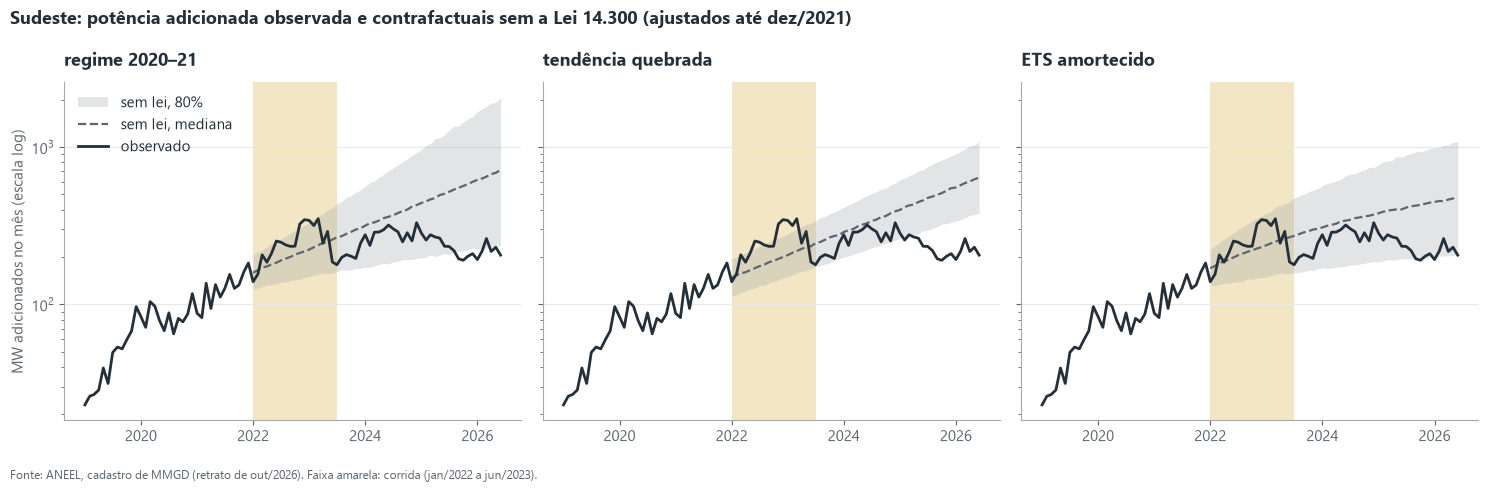

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
obs_se = np.exp(y["SE"])
for ax, nome in zip(axes, CONTRAF):
    s = sims["SE", nome]
    q10, q50, q90 = (np.quantile(s, q, axis=1) for q in (0.1, 0.5, 0.9))
    ax.axvspan(*M.CORRIDA, color=estilo.DESTAQUE, lw=0, zorder=0)
    ax.fill_between(idx_cf, q10, q90, color=estilo.NEUTRO, alpha=0.3, lw=0, label="sem lei, 80%")
    ax.plot(idx_cf, q50, color=estilo.TINTA_SUAVE, lw=1.6, ls="--", label="sem lei, mediana")
    ax.plot(obs_se["2019-01-01":].index, obs_se["2019-01-01":], color=estilo.TINTA, lw=2, label="observado")
    ax.set_title(nome)
    ax.set_yscale("log")
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[0].set_ylabel("MW adicionados no mês (escala log)")
axes[0].legend(loc="upper left")
fig.suptitle("Sudeste: potência adicionada observada e contrafactuais sem a Lei 14.300 (ajustados até dez/2021)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
estilo.fonte_rodape(fig, "Fonte: ANEEL, cadastro de MMGD (retrato de out/2026). Faixa amarela: corrida (jan/2022 a jun/2023).")
fig.savefig(RES / "interv_contrafactual_se.png")

**Leitura (Sudeste).**
- **Corrida:** de jan/2022 a jun/2023 entraram 4,5 GW. Os contrafactuais esperavam de 3,5 a 4,0 GW (mediana), então a corrida acrescentou de **0,5 a 1,0 GW (+12% a +30%)**. A antecipação existe, mas o observado fica dentro da faixa de 80% em dois dos três contrafactuais.
- **Depois:** de jul/2023 a jun/2026 entraram 8,8 GW. Se o ritmo anterior à lei tivesse continuado, seriam de 13,9 a 16,7 GW (mediana). Faltam de **5 a 8 GW (−37% a −47%)**. Só na tendência quebrada o observado fica abaixo do P10 (probabilidade de 3%). Nos outros dois contrafactuais, a parada cabe no leque, que é largo porque projeta 4,5 anos a partir de só 6 anos de dados.
- **Saldo de jan/2022 a jun/2026:** de 4,7 a 7,1 GW a menos que o esperado sem a lei (−26% a −35%). A corrida antecipou menos de 1 GW e o período seguinte perdeu de 5 a 8 GW, então a antecipação não compensa a parada.

**Por UF** (tabela anterior), o padrão se repete em SP e MG. MG teve a maior corrida (+37% sobre o regime 2020–21) e a menor queda depois (−21%). No RJ não há corrida (o observado fica abaixo do contrafactual em 2022–23). Em ES os contrafactuais discordam até no sinal, porque a série é pequena e ruidosa.

**O que o contrafactual não separa.** O "efeito" é tudo o que mudou a partir de 2022 em relação à tendência anterior: a lei, mas também a alta dos juros de 2022–2023, a queda no preço dos módulos e a saturação natural dos primeiros clientes. O degrau de 2020 tira da conta da lei a desaceleração que já vinha acontecendo. O que ele não tira é uma desaceleração que continuaria depois de 2021 sem a lei. O contrafactual ETS amortecido é o que mais se aproxima disso, e mesmo nele faltam 5 GW.

## Conclusões

1. **A desaceleração começou antes da lei.** O crescimento da potência adicionada por mês cai de ~200% ao ano (2016–2019) para ~40% (2020–2021) no Sudeste, com quebra em mar/2020 ($\delta_1$ significativo em SP, MG e no Sudeste).
2. **A corrida de 2022–2023 foi uma antecipação modesta.** Ela não acelerou o crescimento ($\delta_2 pprox 0$ em todas as UFs). Manteve o ritmo de 2020–21 por um ano e meio e acrescentou de 0,5 a 1,0 GW no Sudeste frente aos contrafactuais.
3. **Depois da corrida a potência adicionada parou de crescer.** No Sudeste, ela fica estável em ~200–250 MW por mês desde meados de 2023. Frente ao que se esperava sem a lei, faltam de 5 a 8 GW de jul/2023 a jun/2026. O efeito é significativo com tendência determinística e incerto com tendência estocástica.
4. **Para a fase 4:** o regime pós-corrida é o que deve guiar a previsão. O drift da série inteira (≈ 200% ao ano) não serve. A dúvida entre $d = 0$ e $d = 1$ fica para a validação cruzada.

Limitações: resíduos de MG e ES com autocorrelação na defasagem 10, que ordens até (3, 3) não eliminam (seção 2); datas de quebra fixadas a partir da fase 2 e do calendário da lei, e não estimadas (Bai-Perron seria a extensão); o efeito estimado inclui tudo o que mudou junto com a lei.